In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from scipy import stats as sps
import os, warnings, time

# --- Group configuration ---
group_csv   = "group_gh_ssids.csv"
group_label = "Group G+H"
group_short = "group_gh"

# --- Paths ---
elpac_clean_dir = "../1095 Data/ELPAC/Cleaned"
enrollment_dir  = "../1095 Data/Enrollment"
os.makedirs("plots", exist_ok=True)

# --- Analysis parameters ---
MIN_CELL       = 25    # minimum students per category level
MIN_DISTRICT   = 15    # minimum students per district
MIN_COUNTRY    = 100   # minimum students to keep a birth country separate

pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 200)

print(f"Configured for {group_label}")

# --- CALPADS RaceEthnicity code labels (verified against StudentRace1Code) ---
race_labels = {
    "A": "Asian",
    "B": "Black",
    "D": "NotReported",
    "F": "Filipino",
    "H": "Hispanic_Latino",
    "I": "AmerIndian_AKNative",
    "P": "PacificIslander",
    "T": "TwoOrMore",
    "W": "White",
}
# --- Birth country code → name (ISO 3166-1 alpha-2, plus CALPADS extras) ---
country_labels = {
    # Above the 100-student threshold in this cohort
    "AF": "Afghanistan",   "AM": "Armenia",     "CN": "China",
    "CO": "Colombia",      "GT": "Guatemala",   "HN": "Honduras",
    "HT": "Haiti",         "MX": "Mexico",      "NI": "Nicaragua",
    "RU": "Russia",        "SV": "El Salvador", "UA": "Ukraine",
    "VN": "Vietnam",
    # Non-country levels created by the collapsing step
    "UU": "Unknown",       "Other": "Other (pooled)",  "Missing": "Missing",
    # Below threshold here, but retained in case MIN_COUNTRY is lowered
    "BR": "Brazil",        "PE": "Peru",        "EC": "Ecuador",
    "PH": "Philippines",   "KR": "South Korea", "JP": "Japan",
    "IN": "India",         "PK": "Pakistan",    "BD": "Bangladesh",
    "IQ": "Iraq",          "SY": "Syria",       "YE": "Yemen",
    "EG": "Egypt",         "ET": "Ethiopia",    "SO": "Somalia",
    "KZ": "Kazakhstan",    "UZ": "Uzbekistan",  "MD": "Moldova",
    "BY": "Belarus",       "TH": "Thailand",    "KH": "Cambodia",
    "MM": "Myanmar",       "TR": "Turkey",      "IR": "Iran",
    "JO": "Jordan",        "LB": "Lebanon",     "VE": "Venezuela",
    "AR": "Argentina",     "CL": "Chile",       "DO": "Dominican Rep.",
    "CU": "Cuba",          "TW": "Taiwan",      "HK": "Hong Kong",
    "FJ": "Fiji",          "NP": "Nepal",       "UM": "U.S. Outlying",
    "US": "United States",
}
print(f"Loaded {len(country_labels)} birth country labels")
# --- Outcome switch: flip to Z after seeing Cell 3's verdict ---
OUTCOME  = "ZGain_fixed"      # or "ZGain_fixed"  (orig: "ScoreGain")
BASELINE = "Z1_fixed"         # or "Z1_fixed" (orig: "Summ1Score_c")

print(f"Outcome: {OUTCOME}, baseline covariate: {BASELINE}")

Configured for Group G+H
Loaded 53 birth country labels
Outcome: ZGain_fixed, baseline covariate: Z1_fixed


In [2]:
# --- Group SSIDs ---
group_ssids = set(pd.read_csv(group_csv)["SSID"])
print(f"{group_label}: {len(group_ssids):,} students")

# --- Summative 1 (2022) and Summative 3 (2024) — SAME SCALE ---
def load_summative(filename):
    d = pd.read_csv(os.path.join(elpac_clean_dir, filename), low_memory=False)
    d = d.apply(lambda c: c.str.strip() if c.dtype == "object" else c)
    d["OverallScaleScore"] = pd.to_numeric(d["OverallScaleScore"], errors="coerce")
    d["TestStartDate"]     = pd.to_datetime(d["TestStartDate"], errors="coerce")
    return d

summ1 = load_summative("SummativeElpac_22_clean.csv")
summ3 = load_summative("SummativeElpac_24_clean.csv")
print(f"Summative 2022: {len(summ1):,} rows")
print(f"Summative 2024: {len(summ3):,} rows")

# --- Enrollment (2021-22, the baseline year) ---
enrollment = pd.read_csv(os.path.join(enrollment_dir, "CEnrollment_21-22.csv"), low_memory=False)
enrollment_group = (
    enrollment[enrollment["SSID"].isin(group_ssids)]
    .drop_duplicates(subset="SSID", keep="first")
)
print(f"Enrollment records: {len(enrollment_group):,}")

# --- Verify the scales now match ---
print("\nScale check (these should be comparable):")
print(f"  Summative 2022: min={summ1['OverallScaleScore'].min():.0f}, "
      f"max={summ1['OverallScaleScore'].max():.0f}, mean={summ1['OverallScaleScore'].mean():.0f}")
print(f"  Summative 2024: min={summ3['OverallScaleScore'].min():.0f}, "
      f"max={summ3['OverallScaleScore'].max():.0f}, mean={summ3['OverallScaleScore'].mean():.0f}")

Group G+H: 12,918 students
Summative 2022: 302,476 rows
Summative 2024: 291,920 rows
Enrollment records: 12,918

Scale check (these should be comparable):
  Summative 2022: min=201, max=1950, mean=1476
  Summative 2024: min=201, max=1868, mean=1464


In [3]:
# --- Outcome: Summative 3 − Summative 1 (same scale, valid difference) ---
s1 = (summ1[summ1["SSID"].isin(group_ssids)][["SSID", "OverallScaleScore"]]
      .dropna().rename(columns={"OverallScaleScore": "Summ1Score"}))
s3 = (summ3[summ3["SSID"].isin(group_ssids)][["SSID", "OverallScaleScore"]]
      .dropna().rename(columns={"OverallScaleScore": "Summ3Score"}))

df = s1.merge(s3, on="SSID", how="inner")
df["ScoreGain"] = df["Summ3Score"] - df["Summ1Score"]

# Center the baseline — controls for regression to the mean
df["Summ1Score_c"] = df["Summ1Score"] - df["Summ1Score"].mean()

print(f"Students with both summative scores: {len(df):,}")
print(f"\nOutcome (Summative 2024 − Summative 2022):")
print(df["ScoreGain"].describe())

# --- Sanity check: this should now be a plausible magnitude ---
mean_gain = df["ScoreGain"].mean()
if abs(mean_gain) > 300:
    print(f"\n*** WARNING: mean gain of {mean_gain:.0f} still looks implausible ***")
else:
    print(f"\nMean gain of {mean_gain:.1f} points over two years — plausible.")

Students with both summative scores: 12,918

Outcome (Summative 2024 − Summative 2022):
count    12918.000000
mean       103.504180
std         73.097826
min       -235.000000
25%         55.000000
50%         92.000000
75%        137.000000
max        472.000000
Name: ScoreGain, dtype: float64

Mean gain of 103.5 points over two years — plausible.


In [4]:
# --- Does grade-specific scaling distort the raw-point outcome? ---
# Fixed-reference standardization: BOTH years scaled by the 2022 grade-specific SD.
# Unlike per-year standardization, this preserves between-grade differences.

zdf = df[["SSID", "Summ1Score", "Summ3Score", "ScoreGain"]].copy()
zdf = zdf.merge(
    enrollment_group[["SSID", "GradeLevelCode"]].assign(
        GradeLevelCode=lambda d: d["GradeLevelCode"].astype(str).str.strip()
    ),
    on="SSID", how="left"
)

# --- How much does the scale actually stretch across grades? ---
grade_stats = zdf.groupby("GradeLevelCode")["Summ1Score"].agg(["size", "mean", "std"])
grade_stats.columns = ["N", "Mean_2022", "SD_2022"]
grade_stats = grade_stats.sort_values("SD_2022", ascending=False)

print("2022 SUMMATIVE DISTRIBUTION BY GRADE")
print("=" * 56)
print(grade_stats.to_string())

# Grades with too few students for a stable SD
UNSTABLE_N = 30
unstable = grade_stats[grade_stats["N"] < UNSTABLE_N].index.tolist()
if unstable:
    print(f"\nGrades with N < {UNSTABLE_N} (SD unreliable, excluded from the check): {unstable}")

stable = grade_stats[grade_stats["N"] >= UNSTABLE_N]
sd_ratio = stable["SD_2022"].max() / stable["SD_2022"].min()
print(f"\nSD range across stable grades: {stable['SD_2022'].min():.1f} to "
      f"{stable['SD_2022'].max():.1f}  (ratio {sd_ratio:.2f}x)")

# --- Fixed-reference z-scores: same mu/sd applied to both years ---
g  = zdf.groupby("GradeLevelCode")["Summ1Score"]
mu = g.transform("mean")
sd = g.transform("std")

zdf["Z1_fixed"]    = (zdf["Summ1Score"] - mu) / sd
zdf["Z3_fixed"]    = (zdf["Summ3Score"] - mu) / sd      # SAME mu/sd, not re-derived
zdf["ZGain_fixed"] = zdf["Z3_fixed"] - zdf["Z1_fixed"]

corr = zdf["ZGain_fixed"].corr(zdf["ScoreGain"])

print("\n" + "=" * 56)
print("SCALING CHECK")
print("=" * 56)
print(zdf["ZGain_fixed"].describe().to_string())
print(f"\nCorrelation, fixed-reference z-gain vs raw-point gain: {corr:.4f}")

# --- Per-grade comparison (these should NOT all be zero) ---
by_grade = zdf.groupby("GradeLevelCode").agg(
    N=("ScoreGain", "size"),
    RawGain=("ScoreGain", "mean"),
    ZGain_fixed=("ZGain_fixed", "mean"),
    SD_2022=("Summ1Score", "std"),
).sort_values("RawGain", ascending=False)
by_grade["RawRank"] = by_grade["RawGain"].rank(ascending=False).astype(int)
by_grade["ZRank"]   = by_grade["ZGain_fixed"].rank(ascending=False).astype(int)
by_grade["RankShift"] = by_grade["RawRank"] - by_grade["ZRank"]

print("\nMean gain by grade — raw points vs SD units:")
print(by_grade.to_string())

max_shift = by_grade.loc[by_grade["N"] >= UNSTABLE_N, "RankShift"].abs().max()

print("\n" + "-" * 56)
if corr > 0.95 and max_shift <= 2:
    print("VERDICT: grade scaling is NOT distorting the results.")
    print("Keep ScoreGain — raw points are easier to interpret.")
    USE_Z_OUTCOME = False
else:
    print("*** VERDICT: grade scaling matters. ***")
    print(f"    correlation = {corr:.4f}, max grade rank shift = {max_shift}")
    print("    Refit on ZGain_fixed and compare grade coefficients.")
    USE_Z_OUTCOME = True
print("-" * 56)

# --- Carry the z-outcome forward so the model can use it ---
df = df.merge(zdf[["SSID", "ZGain_fixed", "Z1_fixed"]], on="SSID", how="left")
print(f"\nAdded ZGain_fixed and Z1_fixed to df. Columns: {df.shape[1]}")

2022 SUMMATIVE DISTRIBUTION BY GRADE
                   N    Mean_2022    SD_2022
GradeLevelCode                              
02               914  1330.794311  86.510820
01              1258  1329.647059  85.914396
KN              3583  1353.538376  78.247917
03               868  1374.675115  66.149183
10               541  1418.878004  62.944831
05               708  1385.283898  60.877180
04               832  1381.504808  57.202198
06               722  1402.470914  55.004424
08               695  1414.772662  54.440011
07               752  1408.666223  51.406596
09              1957  1405.065406  49.456606
11                85  1409.917647  48.229662
PS                 3  1372.333333  17.785762

Grades with N < 30 (SD unreliable, excluded from the check): ['PS']

SD range across stable grades: 48.2 to 86.5  (ratio 1.79x)

SCALING CHECK
count    12918.000000
mean         1.552628
std          1.091803
min         -3.578895
25%          0.843473
50%          1.374943
75%         

In [5]:
demo_cols = [
    "SSID", "GradeLevelCode", "SocioeconomicallyDisadvantaged",
    "TitleIPartCMigrant", "HomelessProgram", "Foster",
    "PrimaryLanguageCode", "StudentGenderCode",
    "ParentGuardianHighestEducationLevelCode",
    "RaceEthnicity", "StudentBirthCountryCode", "Districtname",
]
# UnaccompaniedYouthIndicator excluded — 88.9% missing

df = df.merge(enrollment_group[demo_cols], on="SSID", how="left")
print(f"After demographic merge: {len(df):,} students, {df.shape[1]} columns")

# --- Normalize: 'nan'/'none'/'' strings become real NaN ---
raw_cats = [c for c in demo_cols if c not in ("SSID",)]
for col in raw_cats:
    df[col] = df[col].astype(str).str.strip()
    df.loc[df[col].str.lower().isin(["nan", "none", ""]), col] = np.nan

print("\nMissingness after normalization:")
for col in raw_cats:
    n_miss = df[col].isna().sum()
    print(f"  {col:<42} {n_miss:>7,} missing ({n_miss/len(df)*100:>5.1f}%)")

After demographic merge: 12,918 students, 18 columns

Missingness after normalization:
  GradeLevelCode                                   0 missing (  0.0%)
  SocioeconomicallyDisadvantaged                   0 missing (  0.0%)
  TitleIPartCMigrant                               0 missing (  0.0%)
  HomelessProgram                                  0 missing (  0.0%)
  Foster                                           0 missing (  0.0%)
  PrimaryLanguageCode                            216 missing (  1.7%)
  StudentGenderCode                                0 missing (  0.0%)
  ParentGuardianHighestEducationLevelCode         57 missing (  0.4%)
  RaceEthnicity                                    0 missing (  0.0%)
  StudentBirthCountryCode                          0 missing (  0.0%)
  Districtname                                     0 missing (  0.0%)


In [6]:
def collapse_threshold(s, min_n=MIN_CELL, other="Other", missing="Missing",
                       drop_residual=True, verbose=True):
    """
    NOMINAL variables. Levels below min_n pool into 'Other'.

    Unlike the previous version, this RE-CHECKS the pooled bucket: if 'Other'
    still falls below min_n, those rows are set to NaN (drop_residual=True) so
    they can be excluded, rather than becoming an unstable one-off category.
    """
    s = s.copy()
    counts = s.value_counts(dropna=True)
    small = set(counts[counts < min_n].index)

    out = s.apply(lambda x: missing if pd.isna(x) else (other if x in small else x))

    # Re-check every resulting level, including 'Other' and 'Missing'
    post = out.value_counts()
    still_small = [lvl for lvl, n in post.items() if n < min_n]

    if still_small:
        if verbose:
            for lvl in still_small:
                print(f"    post-pool level '{lvl}' has {post[lvl]} < {min_n} "
                      f"→ {'set to NaN' if drop_residual else 'kept'}")
        if drop_residual:
            out = out.where(~out.isin(still_small), np.nan)

    return out


def collapse_ordinal(s, merge_map, missing="Missing"):
    """
    ORDINAL variables (parent education).
    Adjacent levels merged via an explicit map, preserving order.
    Never dump ordinal levels into a generic 'Other' — that destroys the ordering.
    """
    s = s.copy()
    out = s.apply(lambda x: missing if pd.isna(x) else merge_map.get(str(x), str(x)))
    return out


def collapse_domain(s, group_map, other="Other", missing="Missing"):
    """
    Variables with natural structure (grade level → school stage).
    Mapping is supplied explicitly by domain knowledge.
    """
    s = s.copy()
    out = s.apply(lambda x: missing if pd.isna(x) else group_map.get(str(x), other))
    return out


def report_collapse(before, after, name):
    print(f"\n{name}")
    print(f"  before: {before.nunique(dropna=True):>3} levels, {before.isna().sum():>6,} missing")
    print(f"  after:  {after.nunique():>3} levels")
    vc = after.value_counts()
    for val, n in vc.items():
        flag = "  <-- below MIN_CELL" if n < MIN_CELL else ""
        print(f"    {str(val):<28} {n:>7,}{flag}")

In [7]:
work = df.copy()

# --- Birth country grouping (before other work) ---
# (keep whatever you already have here for BirthCountryGroup if it differs)

# --- Nominal, threshold-collapsed ---
print("Grade:")
work["Grade"]        = collapse_threshold(work["GradeLevelCode"],          min_n=MIN_CELL)
print("Race:")
work["Race"] = work["RaceEthnicity"].map(race_labels).fillna(work["RaceEthnicity"])
work["Race"] = collapse_threshold(work["Race"], min_n=MIN_CELL)
print("BirthCountry:")
work["BirthCountry"] = collapse_threshold(work["StudentBirthCountryCode"], min_n=MIN_COUNTRY)

# --- Ordinal ---
parent_ed_map = {
    "10.0": "1_NotHSGrad",   "10": "1_NotHSGrad",
    "11.0": "2_HSGrad",      "11": "2_HSGrad",
    "12.0": "3_SomeCollege", "12": "3_SomeCollege",
    "13.0": "4_CollegePlus", "13": "4_CollegePlus",
    "14.0": "4_CollegePlus", "14": "4_CollegePlus",
    "15.0": "5_Declined",    "15": "5_Declined",
}
work["ParentEd"] = collapse_ordinal(work["ParentGuardianHighestEducationLevelCode"], parent_ed_map)

# --- Language ---
lang = work["PrimaryLanguageCode"]
work["Language"] = np.select([lang.isna(), lang == "01"],
                             ["Unknown", "Spanish"], default="Non-Spanish")

# --- Binaries: these previously bypassed collapsing entirely ---
for col, new in [
    ("StudentGenderCode",              "Gender"),
    ("SocioeconomicallyDisadvantaged", "SED"),
    ("TitleIPartCMigrant",             "Migrant"),
    ("HomelessProgram",                "Homeless"),
    ("Foster",                         "Foster"),
]:
    print(f"{new}:")
    work[new] = collapse_threshold(work[col], min_n=MIN_CELL)

# --- Report ---
for src, new in [
    ("GradeLevelCode", "Grade"),
    ("ParentGuardianHighestEducationLevelCode", "ParentEd"),
    ("RaceEthnicity", "Race"),
    ("StudentBirthCountryCode", "BirthCountry"),
    ("PrimaryLanguageCode", "Language"),
    ("StudentGenderCode", "Gender"),
    ("SocioeconomicallyDisadvantaged", "SED"),
    ("TitleIPartCMigrant", "Migrant"),
    ("HomelessProgram", "Homeless"),
    ("Foster", "Foster"),
]:
    report_collapse(df[src], work[new], new)

Grade:
    post-pool level 'Other' has 3 < 25 → set to NaN
Race:
    post-pool level 'Other' has 14 < 25 → set to NaN
BirthCountry:
Gender:
    post-pool level 'Other' has 1 < 25 → set to NaN
SED:
Migrant:
Homeless:
Foster:
    post-pool level 'Other' has 16 < 25 → set to NaN

Grade
  before:  13 levels,      0 missing
  after:   12 levels
    KN                             3,583
    09                             1,957
    01                             1,258
    02                               914
    03                               868
    04                               832
    07                               752
    06                               722
    05                               708
    08                               695
    10                               541
    11                                85

ParentEd
  before:   6 levels,     57 missing
  after:    6 levels
    4_CollegePlus                  5,468
    5_Declined                     4,733
    2_HSGrad    

In [8]:
model_cats = ["Grade", "ParentEd", "Race", "BirthCountry", "Language",
              "Gender", "SED", "Migrant", "Homeless"] # Foster removed

# --- Districts: drop small ones ---
work["District"] = work["Districtname"].fillna("Missing")
dsize = work["District"].value_counts()
small_d = dsize[dsize < MIN_DISTRICT].index.tolist()
if small_d:
    print(f"Dropping {len(small_d)} districts with <{MIN_DISTRICT} students "
          f"({dsize[small_d].sum():,} students)")
    work = work[~work["District"].isin(small_d)]

# --- Drop students left in unusable categories by the post-pool check ---
n_before = len(work)
work = work.dropna(subset=model_cats)
n_dropped = n_before - len(work)
print(f"Dropped {n_dropped} students in below-minimum categories "
      f"({n_dropped/n_before*100:.2f}%)")

# --- Outcome must be present ---
model_df = work.dropna(subset=[OUTCOME, BASELINE]).reset_index(drop=True)

print(f"\n{'='*64}")
print(f"FINAL MODELING DATASET — {group_label}")
print(f"{'='*64}")
print(f"Students:   {len(model_df):>8,}  ({len(model_df)/len(df)*100:.1f}% of {len(df):,} retained)")
print(f"Districts:  {model_df['District'].nunique():>8,}")
print(f"Outcome:    {OUTCOME}")
print(f"Mean:       {model_df[OUTCOME].mean():>8.3f} (SD {model_df[OUTCOME].std():.3f})")
print(f"{'='*64}")

# --- Hard check: nothing below MIN_CELL reaches the model ---
print("\nFinal cell-size check:")
violations = []
for col in model_cats:
    vc = model_df[col].value_counts()
    bad = vc[vc < MIN_CELL]
    if len(bad):
        violations.append((col, bad.to_dict()))
        print(f"  *** {col}: {bad.to_dict()}")
    else:
        print(f"  {col:<16} {vc.nunique():>2} levels, smallest = {vc.min():,}")

assert not violations, f"Cells below MIN_CELL={MIN_CELL}: {violations}"
print("\nAll cells meet minimum size.")

Dropped 18 students in below-minimum categories (0.14%)

FINAL MODELING DATASET — Group G+H
Students:     12,900  (99.9% of 12,918 retained)
Districts:        23
Outcome:    ZGain_fixed
Mean:          1.551 (SD 1.089)

Final cell-size check:
  Grade            12 levels, smallest = 85
  ParentEd          6 levels, smallest = 57
  Race              8 levels, smallest = 47
  BirthCountry     15 levels, smallest = 99
  Language          3 levels, smallest = 214
  Gender            2 levels, smallest = 6,012
  SED               2 levels, smallest = 3,025
  Migrant           2 levels, smallest = 165
  Homeless          2 levels, smallest = 1,426

All cells meet minimum size.


In [9]:
fixed_cat = model_cats   # District is the random effect

RACE_REF = "Hispanic_Latino"
race_levels = set(model_df["Race"].unique())
if RACE_REF not in race_levels:
    raise ValueError(
        f"Reference level '{RACE_REF}' not found in Race.\n"
        f"Found: {sorted(race_levels)}"
    )

# --- Build the term list once; reused by the LRT cell ---
def build_formula(outcome, baseline, terms):
    rhs = [baseline] + [
        f'C({v}, Treatment(reference="{RACE_REF}"))' if v == "Race" else f"C({v})"
        for v in terms
    ]
    return f"{outcome} ~ " + " + ".join(rhs)

full_formula = build_formula(OUTCOME, BASELINE, fixed_cat)
print(full_formula, "\n")

t0 = time.time()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    full_model = smf.mixedlm(
        full_formula, data=model_df, groups="District"
    ).fit(reml=True, method="lbfgs", maxiter=2000)
print(f"Fitted in {time.time()-t0:.1f}s — converged: {full_model.converged}\n")

print(full_model.summary())

vb = float(full_model.cov_re.iloc[0, 0])
vw = float(full_model.scale)
icc = vb / (vb + vw)

unit = "points" if OUTCOME == "ScoreGain" else "SD units"

print(f"\n{'='*64}")
print(f"VARIANCE DECOMPOSITION  (outcome: {OUTCOME})")
print(f"{'='*64}")
print(f"Between-district variance: {vb:>10.4f}  (SD {np.sqrt(vb):.4f} {unit})")
print(f"Within-district variance:  {vw:>10.4f}  (SD {np.sqrt(vw):.4f} {unit})")
print(f"ICC = {icc:.4f} → {icc*100:.2f}% of variation is between districts")
print(f"{'='*64}")

ZGain_fixed ~ Z1_fixed + C(Grade) + C(ParentEd) + C(Race, Treatment(reference="Hispanic_Latino")) + C(BirthCountry) + C(Language) + C(Gender) + C(SED) + C(Migrant) + C(Homeless) 

Fitted in 0.3s — converged: True

                                    Mixed Linear Model Regression Results
Model:                               MixedLM                  Dependent Variable:                  ZGain_fixed
No. Observations:                    12900                    Method:                              REML       
No. Groups:                          23                       Scale:                               0.8850     
Min. group size:                     27                       Log-Likelihood:                      -17616.6273
Max. group size:                     5397                     Converged:                           Yes        
Mean group size:                     560.9                                                                    
----------------------------------------------

In [10]:
# --- Fit both outcomes; compare grade coefficients ---
comp_models = {}
for outc, base in [("ScoreGain", "Summ1Score_c"), ("ZGain_fixed", "Z1_fixed")]:
    if outc not in model_df.columns or base not in model_df.columns:
        print(f"SKIP {outc}: column missing — did Cell 3 run?")
        continue
    f = build_formula(outc, base, fixed_cat)
    sub = model_df.dropna(subset=[outc, base])
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = smf.mixedlm(f, data=sub, groups="District").fit(
            reml=True, method="lbfgs", maxiter=2000)
    comp_models[outc] = m
    print(f"{outc:<14} n={len(sub):,}  converged={m.converged}")

if len(comp_models) == 2:
    raw_g = comp_models["ScoreGain"].fe_params.filter(like="C(Grade)")
    z_g   = comp_models["ZGain_fixed"].fe_params.filter(like="C(Grade)")

    grade_comp = pd.DataFrame({
        "Grade":     raw_g.index.str.extract(r"\[T\.(.+?)\]")[0].values,
        "Raw_pts":   raw_g.values,
        "Z_SDunits": z_g.reindex(raw_g.index).values,
    })
    grade_comp["Raw_rank"] = grade_comp["Raw_pts"].rank(ascending=False).astype(int)
    grade_comp["Z_rank"]   = grade_comp["Z_SDunits"].rank(ascending=False).astype(int)
    grade_comp["Shift"]    = grade_comp["Raw_rank"] - grade_comp["Z_rank"]

    print("\n" + "="*70)
    print("GRADE COEFFICIENTS — raw points vs SD units")
    print("="*70)
    print(grade_comp.sort_values("Raw_pts", ascending=False).to_string(index=False))

    max_shift = int(grade_comp["Shift"].abs().max())
    rank_corr = grade_comp["Raw_pts"].corr(grade_comp["Z_SDunits"], method="spearman")
    print("-"*70)
    print(f"Max rank shift: {max_shift}   |   Spearman correlation: {rank_corr:.3f}")

    if max_shift <= 2 and rank_corr > 0.90:
        print("\nVERDICT: grade ordering is STABLE across scalings.")
        print("Report the raw-point results — they are easier to interpret.")
    else:
        print("\n*** VERDICT: grade ordering CHANGES with scaling. ***")
        print("The raw-point grade ranking is a scaling artifact.")
        print("Set OUTCOME='ZGain_fixed', BASELINE='Z1_fixed' in Cell 0 and re-run.")
    print("="*70)

ScoreGain      n=12,900  converged=True
ZGain_fixed    n=12,900  converged=True

GRADE COEFFICIENTS — raw points vs SD units
Grade    Raw_pts  Z_SDunits  Raw_rank  Z_rank  Shift
   02   8.890862   0.080976         1       6     -5
   03   1.174576   0.099726         2       5     -3
   05   0.826636   0.137237         3       4     -1
   04  -0.391267   0.269785         4       1      3
   10  -2.234866  -0.272033         5      11     -6
   11  -3.823645   0.140327         6       3      3
   09  -3.912296   0.183190         7       2      5
   06  -4.202657   0.050744         8       7      1
   08 -12.355133  -0.215023         9      10     -1
   KN -12.849434  -0.176959        10       9      1
   07 -15.288466  -0.119820        11       8      3
----------------------------------------------------------------------
Max rank shift: 6   |   Spearman correlation: 0.427

*** VERDICT: grade ordering CHANGES with scaling. ***
The raw-point grade ranking is a scaling artifact.
Set OUTCOM

In [11]:
params = full_model.fe_params
pvals  = full_model.pvalues[params.index]

def var_effects(varname):
    mask = params.index.str.startswith(f"C({varname}")   # note: no closing paren
    if not mask.any():
        return None
    coefs  = params[mask]
    levels = coefs.index.str.extract(r"\[T\.(.+?)\]")[0].tolist()
    e = pd.DataFrame({
        "Level":  levels + ["(reference)"],
        "Effect": coefs.values.tolist() + [0.0],
        "P":      pvals[mask].values.tolist() + [np.nan],
    })
    counts = model_df[varname].value_counts()
    ref_level = set(counts.index) - set(levels)
    e["N"] = e["Level"].map(counts)
    if ref_level:
        e.loc[e["Level"] == "(reference)", "N"] = counts[list(ref_level)[0]]
        e.loc[e["Level"] == "(reference)", "Level"] = f"{list(ref_level)[0]} (ref)"
    return e

rows = []
for v in fixed_cat:
    e = var_effects(v)
    if e is None:
        continue

    # Restrict to levels meeting the minimum before picking the "largest"
    e_valid = e[(e["N"] >= MIN_CELL) | e["N"].isna()]
    if len(e_valid) == 0:
        e_valid = e

    idx = e_valid["Effect"].abs().idxmax()

    rows.append({
        "Variable":      v,
        "Type":          "Fixed",
        "N_Levels":      len(e),
        # Range also computed on valid levels only
        "EffectRange":   e_valid["Effect"].max() - e_valid["Effect"].min(),
        "LargestLevel":  e_valid.loc[idx, "Level"],
        "LargestEffect": e_valid.loc[idx, "Effect"],
        "LargestN":      e_valid.loc[idx, "N"],
        "LargestP":      e_valid.loc[idx, "P"],
        "N_Significant": int((e["P"] < 0.05).sum()),
    })

# if "Summ1Score_c" in params.index:
#     spread = model_df["Summ1Score_c"].max() - model_df["Summ1Score_c"].min()
#     rows.append({
#         "Variable": "Summ1Score_c", "Type": "Fixed (continuous)", "N_Levels": np.nan,
#         "EffectRange": abs(params["Summ1Score_c"] * spread),
#         "LargestLevel": "per 1 point", "LargestEffect": params["Summ1Score_c"],
#         "LargestN": len(model_df),
#         "N_Significant": int(pvals["Summ1Score_c"] < 0.05),
#     })
if BASELINE in params.index:
    spread = model_df[BASELINE].max() - model_df[BASELINE].min()
    rows.append({
        "Variable": BASELINE, "Type": "Fixed (continuous)", "N_Levels": np.nan,
        "EffectRange": abs(params[BASELINE] * spread),
        "LargestLevel": "per 1 unit", "LargestEffect": params[BASELINE],
        "LargestN": len(model_df),
        "LargestP": pvals[BASELINE],
        "N_Significant": int(pvals[BASELINE] < 0.05),
    })


re_vals = np.array([np.asarray(v).ravel()[0] for v in full_model.random_effects.values()])
top_d = max(full_model.random_effects,
            key=lambda k: abs(np.asarray(full_model.random_effects[k]).ravel()[0]))
rows.append({
    "Variable": "District", "Type": "Random", "N_Levels": len(re_vals),
    "EffectRange": re_vals.max() - re_vals.min(),
    "LargestLevel": top_d, "LargestEffect": re_vals[np.argmax(np.abs(re_vals))],
    "LargestN": model_df["District"].value_counts()[top_d],
    "N_Significant": np.nan,
})

effects_df = pd.DataFrame(rows)
print(effects_df.sort_values("EffectRange", ascending=False).to_string(index=False))

    Variable               Type  N_Levels  EffectRange         LargestLevel  LargestEffect  LargestN     LargestP  N_Significant
    Z1_fixed Fixed (continuous)       NaN     5.075652           per 1 unit      -0.492205   12900.0 0.000000e+00            1.0
BirthCountry              Fixed      15.0     0.789215                   GT      -0.489605    2538.0 3.946791e-15            9.0
       Grade              Fixed      12.0     0.541818                   10      -0.272033     541.0 4.573325e-08            9.0
    District             Random      23.0     0.472543 Grossmont Union High      -0.265433      75.0          NaN            NaN
        Race              Fixed       8.0     0.468686                Black      -0.235424     177.0 1.227140e-02            2.0
    ParentEd              Fixed       6.0     0.293030              Missing      -0.262566      57.0 6.888870e-02            2.0
    Language              Fixed       3.0     0.143938              Spanish       0.143938    774

In [12]:
print("Fitting ML baseline...")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    full_ml = smf.mixedlm(full_formula, data=model_df, groups="District").fit(
        reml=False, method="lbfgs", maxiter=2000)
ll_full, k_full = full_ml.llf, len(full_ml.fe_params)
print(f"Log-likelihood: {ll_full:.2f}\n")

all_terms = [BASELINE] + fixed_cat
lrt_rows = []

for v in all_terms:
    if v == BASELINE:
        red_formula = f"{OUTCOME} ~ " + " + ".join(
            f'C({t}, Treatment(reference="{RACE_REF}"))' if t == "Race" else f"C({t})"
            for t in fixed_cat)
    else:
        red_formula = build_formula(OUTCOME, BASELINE, [t for t in fixed_cat if t != v])

    print(f"  dropping {v:<16}", end=" ", flush=True)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            red = smf.mixedlm(red_formula, data=model_df, groups="District").fit(
                reml=False, method="lbfgs", maxiter=2000)
        lr = 2 * (ll_full - red.llf)
        dfd = k_full - len(red.fe_params)
        p = sps.chi2.sf(lr, dfd) if dfd > 0 else np.nan
        lrt_rows.append({"Variable": v, "LR_ChiSq": lr, "df": dfd, "LRT_P": p})
        print(f"chi2={lr:>8.1f}  p={p:.2e}")
    except Exception as ex:
        print(f"FAILED: {ex}")
        lrt_rows.append({"Variable": v, "LR_ChiSq": np.nan, "df": np.nan, "LRT_P": np.nan})

# District variance component (boundary test — halve the p-value)
print(f"  dropping {'District':<16}", end=" ", flush=True)
ols_equiv = smf.ols(full_formula, data=model_df).fit()
lr_d = 2 * (ll_full - ols_equiv.llf)
p_d_halved   = 0.5 * sps.chi2.sf(lr_d, 1)
p_d_unhalved = sps.chi2.sf(lr_d, 1)
lrt_rows.append({"Variable": "District", "LR_ChiSq": lr_d, "df": 1, "LRT_P": p_d_halved})
print(f"chi2={lr_d:>8.1f}  p={p_d_halved:.2e}")

lrt_df = pd.DataFrame(lrt_rows)

# --- Boundary test documentation ---
print("\n" + "-" * 64)
print("BOUNDARY TEST NOTE (district variance component)")
print("-" * 64)
print("Testing a variance component against zero puts the null on the")
print("boundary of the parameter space. P-value halved per Self & Liang (1987).")
print(f"  halved (reported):  p = {p_d_halved:.2e}")
print(f"  unhalved (conservative): p = {p_d_unhalved:.2e}")
print("Conclusion is unchanged either way." if p_d_unhalved < 0.05
      else "*** Conclusion DIFFERS between the two — report both. ***")
print("-" * 64)

# --- Multiple comparison corrections ---
from statsmodels.stats.multitest import multipletests

lrt_valid = lrt_df.dropna(subset=["LRT_P"]).copy()
rej_bonf, p_bonf, _, _ = multipletests(lrt_valid["LRT_P"], alpha=0.05, method="bonferroni")
rej_bh,   p_bh,   _, _ = multipletests(lrt_valid["LRT_P"], alpha=0.05, method="fdr_bh")

lrt_valid["P_Bonferroni"] = p_bonf
lrt_valid["P_BH_FDR"]     = p_bh
lrt_valid["Sig_Raw"]      = lrt_valid["LRT_P"] < 0.05
lrt_valid["Sig_Bonf"]     = rej_bonf
lrt_valid["Sig_BH"]       = rej_bh

lrt_df = lrt_df.merge(
    lrt_valid[["Variable", "P_Bonferroni", "P_BH_FDR", "Sig_Raw", "Sig_Bonf", "Sig_BH"]],
    on="Variable", how="left"
)

print("\n" + "=" * 88)
print(f"MULTIPLE COMPARISON CORRECTION ({len(lrt_valid)} tests)")
print("=" * 88)
print(lrt_df[["Variable", "LR_ChiSq", "LRT_P", "P_Bonferroni", "P_BH_FDR",
              "Sig_Raw", "Sig_Bonf", "Sig_BH"]].to_string(index=False))
print("-" * 88)
print(f"Significant — raw: {lrt_df['Sig_Raw'].sum()}, "
      f"Bonferroni: {lrt_df['Sig_Bonf'].sum()}, BH-FDR: {lrt_df['Sig_BH'].sum()}")

lost = lrt_df[lrt_df["Sig_Raw"] & ~lrt_df["Sig_Bonf"].fillna(False)]["Variable"].tolist()
if lost:
    print(f"\nSignificant at p<0.05 but NOT after Bonferroni: {lost}")
    print("  → treat these as suggestive, not established.")
print("=" * 88)

Fitting ML baseline...
Log-likelihood: -17517.89

  dropping Z1_fixed         chi2=  2847.2  p=0.00e+00
  dropping Grade            chi2=   376.3  p=6.45e-74
  dropping ParentEd         chi2=    96.2  p=3.41e-19
  dropping Race             chi2=    15.0  p=3.57e-02
  dropping BirthCountry     chi2=   185.3  p=5.53e-32
  dropping Language         chi2=    10.3  p=5.75e-03
  dropping Gender           chi2=    16.6  p=4.55e-05
  dropping SED              chi2=    10.4  p=1.25e-03
  dropping Migrant          chi2=     0.3  p=5.76e-01
  dropping Homeless         chi2=     0.5  p=4.71e-01
  dropping District         chi2=   163.9  p=8.11e-38

----------------------------------------------------------------
BOUNDARY TEST NOTE (district variance component)
----------------------------------------------------------------
Testing a variance component against zero puts the null on the
boundary of the parameter space. P-value halved per Self & Liang (1987).
  halved (reported):  p = 8.11e-38
  unh

In [13]:
imp = effects_df.merge(lrt_df, on="Variable", how="left")
imp["Score_Range"] = 100 * imp["EffectRange"] / imp["EffectRange"].max()
imp["Score_LRT"]   = 100 * imp["LR_ChiSq"]    / imp["LR_ChiSq"].max()
imp = imp.sort_values("Score_LRT", ascending=False).reset_index(drop=True)
imp.insert(0, "Rank", range(1, len(imp) + 1))

readable = {
    "Summ1Score_c": "Baseline Score (2022)", 
    "Z1_fixed": "Baseline Score (SD units)",
    "Grade": "Grade Level (2022)",
    "ParentEd": "Parent Education", 
    "Race": "Race / Ethnicity",
    "BirthCountry": "Birth Country", 
    "Language": "Primary Language",
    "Gender": "Gender", 
    "SED": "Socioeconomically Disadv.",
    "Migrant": "Migrant Status", 
    "Homeless": "Homeless", 
    "Foster": "Foster Care",
    "District": "School District",
}
imp["Label"] = imp["Variable"].map(readable).fillna(imp["Variable"])

pd.set_option("display.float_format", "{:.2f}".format)
print("=" * 118)
print(f"{group_label} — VARIABLE IMPORTANCE  (outcome: Summative 2024 − Summative 2022)")
print("=" * 118)
cols = ["Rank", "Label", "Type", "EffectRange", "LargestLevel", "LargestEffect",
        "LargestN", "LR_ChiSq", "LRT_P"]
cols += [c for c in ["P_BH_FDR", "Sig_Bonf", "Sig_BH"] if c in imp.columns]
print(imp[cols].to_string(index=False))
print("=" * 118)

imp.to_csv(f"variable_importance_{group_short}.csv", index=False)
print(f"\nSaved: variable_importance_{group_short}.csv")

Group G+H — VARIABLE IMPORTANCE  (outcome: Summative 2024 − Summative 2022)
 Rank                     Label               Type  EffectRange         LargestLevel  LargestEffect  LargestN  LR_ChiSq  LRT_P  P_BH_FDR  Sig_Bonf  Sig_BH
    1 Baseline Score (SD units) Fixed (continuous)         5.08           per 1 unit          -0.49  12900.00   2847.16   0.00      0.00      True    True
    2        Grade Level (2022)              Fixed         0.54                   10          -0.27    541.00    376.32   0.00      0.00      True    True
    3             Birth Country              Fixed         0.79                   GT          -0.49   2538.00    185.26   0.00      0.00      True    True
    4           School District             Random         0.47 Grossmont Union High          -0.27     75.00    163.86   0.00      0.00      True    True
    5          Parent Education              Fixed         0.29              Missing          -0.26     57.00     96.15   0.00      0.00      True   

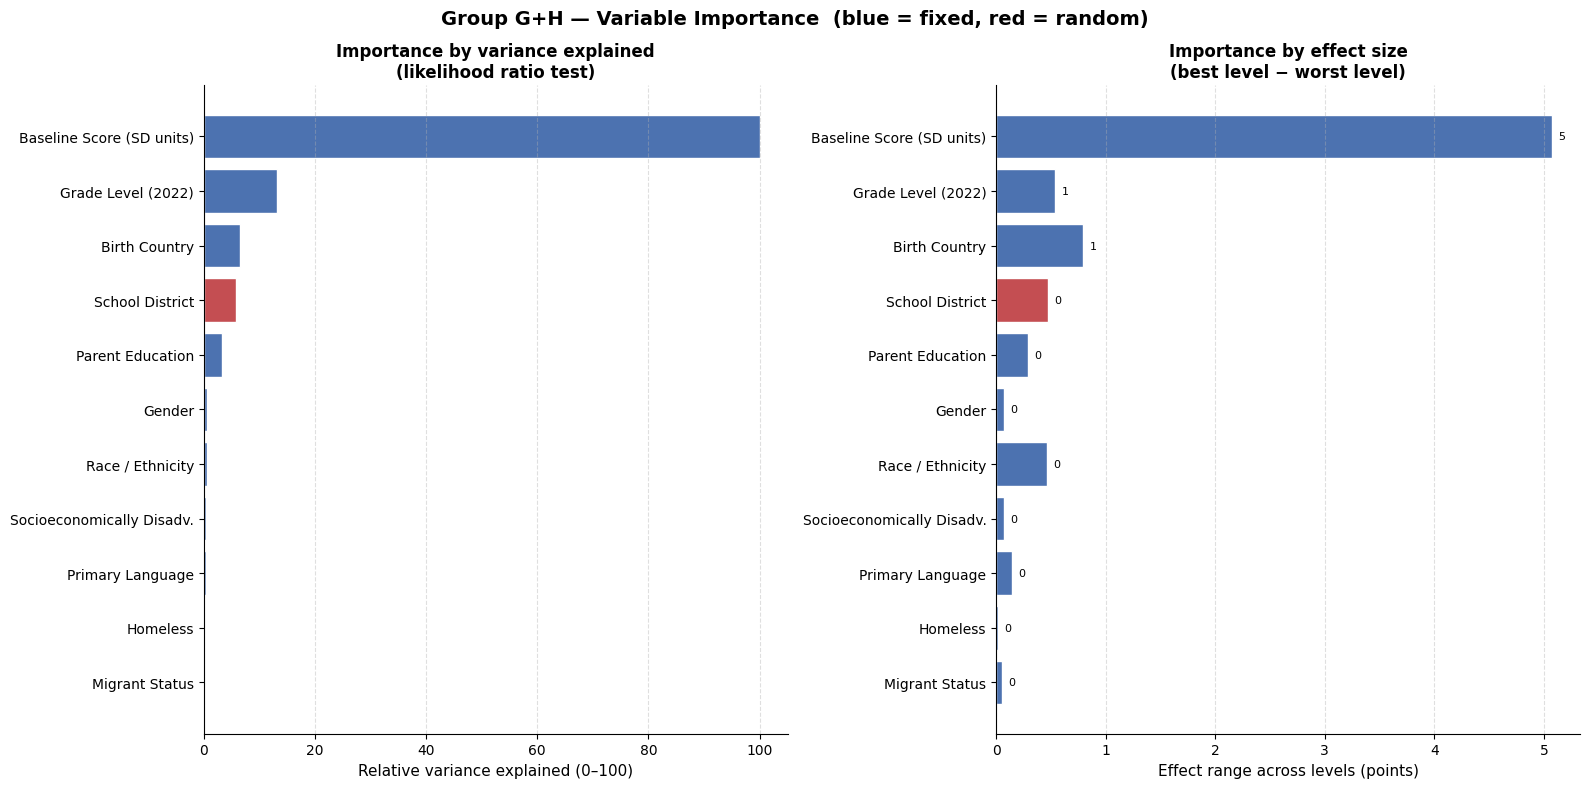

Saved: plots/group_gh_variable_importance.png


In [14]:
plot_df = imp.sort_values("Score_LRT", ascending=True)
colors = ["#C44E52" if t == "Random" else "#4C72B0" for t in plot_df["Type"]]

fig, axes = plt.subplots(1, 2, figsize=(16, 8))

axes[0].barh(plot_df["Label"], plot_df["Score_LRT"], color=colors, edgecolor="white")
axes[0].set_xlabel("Relative variance explained (0–100)", fontsize=11)
axes[0].set_title("Importance by variance explained\n(likelihood ratio test)",
                  fontsize=12, fontweight="bold")

axes[1].barh(plot_df["Label"], plot_df["EffectRange"], color=colors, edgecolor="white")
for i, (_, r) in enumerate(plot_df.iterrows()):
    axes[1].text(r["EffectRange"], i, f"  {r['EffectRange']:.0f}", va="center", fontsize=8)
axes[1].set_xlabel("Effect range across levels (points)", fontsize=11)
axes[1].set_title("Importance by effect size\n(best level − worst level)",
                  fontsize=12, fontweight="bold")

for ax in axes:
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(f"{group_label} — Variable Importance  (blue = fixed, red = random)",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"plots/{group_short}_variable_importance.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: plots/{group_short}_variable_importance.png")

In [15]:
# --- Per-level detail for the top fixed effects, with readable labels ---

# Label maps applied at display time only; the model still uses raw codes.
LEVEL_LABELS = {
    "BirthCountry": country_labels,
    # "Race": race_labels,   # already mapped at source in Cell 6
}

def prettify(e, varname):
    """Map coded levels to full names for display. Preserves '(ref)' markers."""
    lut = LEVEL_LABELS.get(varname)
    if lut is None:
        return e
    e = e.copy()

    def relabel(lvl):
        lvl = str(lvl)
        # var_effects marks the reference row as "XX (ref)" — map the code, keep the marker
        if lvl.endswith(" (ref)"):
            code = lvl[:-6]
            return f"{lut.get(code, code)} (ref)"
        return lut.get(lvl, lvl)

    e["Level"] = e["Level"].map(relabel)
    return e


for v in imp[imp["Type"] == "Fixed"]["Variable"].head(6):
    e = var_effects(v)
    if e is None:
        continue
    e = prettify(e, v)
    e = e.sort_values("Effect", ascending=False)
    print(f"\n{'='*72}\n{readable.get(v, v)}\n{'='*72}")
    print(e.to_string(index=False))

    # Flag any level that didn't find a label
    lut = LEVEL_LABELS.get(v)
    if lut is not None:
        unmapped = [l for l in e["Level"]
                    if l not in lut.values() and not l.endswith(" (ref)")]
        if unmapped:
            print(f"\n  NOTE: no label found for {unmapped} — add to country_labels in Cell 0")

re_df = pd.DataFrame([
    {"District": d, "Effect": float(np.asarray(val).ravel()[0])}
    for d, val in full_model.random_effects.items()
])
re_df["N"] = re_df["District"].map(model_df["District"].value_counts())
re_df = re_df.sort_values("Effect", ascending=False)
print(f"\n{'='*72}\nSchool District (shrunken random effects)\n{'='*72}")
print(re_df.to_string(index=False))

unit = "points" if OUTCOME == "ScoreGain" else "SD units"
print(f"\nICC = {icc:.4f}  |  district SD = {np.sqrt(vb):.2f} {unit}")


Grade Level (2022)
   Level  Effect    P       N
      04    0.27 0.00  830.00
      09    0.18 0.00 1957.00
      11    0.14 0.20   85.00
      05    0.14 0.00  708.00
      03    0.10 0.02  866.00
      02    0.08 0.05  913.00
      06    0.05 0.25  721.00
01 (ref)    0.00  NaN 1257.00
      07   -0.12 0.01  751.00
      KN   -0.18 0.00 3576.00
      08   -0.22 0.00  695.00
      10   -0.27 0.00  541.00

Birth Country
            Level  Effect    P       N
          Ukraine    0.30 0.00  203.00
           Russia    0.22 0.00  426.00
            Haiti    0.19 0.11   99.00
          Vietnam    0.16 0.06  188.00
          Armenia    0.12 0.07  477.00
   Other (pooled)    0.04 0.33 1266.00
Afghanistan (ref)    0.00  NaN 2111.00
            China   -0.00 0.95  235.00
         Colombia   -0.22 0.01  258.00
           Mexico   -0.23 0.00 1780.00
        Nicaragua   -0.24 0.00  319.00
      El Salvador   -0.34 0.00 1863.00
         Honduras   -0.43 0.00  971.00
          Unknown   -0.46 0.0

In [16]:
# ==============================================================
# BIRTH COUNTRY × LANGUAGE — CONFOUNDING DIAGNOSTIC
# ==============================================================
# Two variables that encode nearly the same information cannot be
# interpreted individually in a joint model. This cell measures how
# much they overlap before we fit anything.

from scipy.stats import chi2_contingency

ct = pd.crosstab(model_df["BirthCountry"], model_df["Language"])
print("CROSS-TABULATION: Birth Country × Language")
print("=" * 62)
print(ct.to_string())

# --- Percent of each country that is Spanish-speaking ---
pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
print("\n\nPercent of each birth country by language:")
print("=" * 62)
print(pct.to_string())

# --- Cramér's V: 0 = independent, 1 = one perfectly predicts the other ---
chi2, p, dof, _ = chi2_contingency(ct)
n = ct.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

print("\n" + "=" * 62)
print(f"Cramér's V = {cramers_v:.4f}")
print(f"  chi2 = {chi2:,.1f}, dof = {dof}, p = {p:.2e}")
print("-" * 62)
if cramers_v > 0.7:
    print("SEVERE overlap — these variables encode nearly the same information.")
    print("Joint coefficients for BOTH are uninterpretable.")
elif cramers_v > 0.4:
    print("MODERATE overlap — joint coefficients are attenuated and unstable.")
else:
    print("MILD overlap — both can reasonably stay in the model.")
print("=" * 62)

# --- How cleanly does language partition the countries? ---
dominant = pct.idxmax(axis=1)
purity   = pct.max(axis=1)
print("\nDominant language per country (purity = % in that language):")
summary_ct = pd.DataFrame({
    "N": ct.sum(axis=1),
    "DominantLang": dominant,
    "Purity_%": purity.round(1),
}).sort_values("N", ascending=False)
print(summary_ct.to_string())

near_pure = (purity >= 95).sum()
print(f"\n{near_pure} of {len(purity)} countries are ≥95% one language.")
print("The higher this is, the more redundant the two variables are.")

CROSS-TABULATION: Birth Country × Language
Language      Non-Spanish  Spanish  Unknown
BirthCountry                               
AF                   2038        1       72
AM                    468        0        9
CN                    232        0        3
CO                      0      253        5
GT                    261     2246       31
HN                      2      955       14
HT                     74       25        0
MX                     15     1747       18
NI                      0      315        4
Other                1017      230       19
RU                    421        1        4
SV                      0     1836       27
UA                    201        0        2
UU                     25      136        5
VN                    187        0        1


Percent of each birth country by language:
Language      Non-Spanish  Spanish  Unknown
BirthCountry                               
AF                  96.50     0.00     3.40
AM                  98.10     0.

In [17]:
# ==============================================================
# FIT FOUR MODELS TO SEPARATE THE TWO EFFECTS
# ==============================================================
#   1. BOTH      — current specification
#   2. COUNTRY   — birth country only, language dropped
#   3. LANGUAGE  — language only, birth country dropped
#   4. NEITHER   — baseline for comparison
#
# ML (reml=False) is required: models with DIFFERENT fixed-effect
# sets have REML likelihoods that are not comparable.

specs = {
    "BOTH":     [t for t in fixed_cat],
    "COUNTRY":  [t for t in fixed_cat if t != "Language"],
    "LANGUAGE": [t for t in fixed_cat if t != "BirthCountry"],
    "NEITHER":  [t for t in fixed_cat if t not in ("BirthCountry", "Language")],
}

fits = {}
print("Fitting four models with ML...\n")
for name, terms in specs.items():
    f = build_formula(OUTCOME, BASELINE, terms)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = smf.mixedlm(f, data=model_df, groups="District").fit(
            reml=False, method="lbfgs", maxiter=2000)
    fits[name] = m
    print(f"  {name:<9} k={len(m.fe_params):>3}  logLik={m.llf:>12.2f}  "
          f"AIC={m.aic:>11.1f}  converged={m.converged}")

# --- Incremental contribution of each variable ---
print("\n" + "=" * 74)
print("INCREMENTAL CONTRIBUTION (likelihood ratio tests)")
print("=" * 74)

comparisons = [
    ("Language added to a model that already has Country",  "COUNTRY",  "BOTH"),
    ("Country added to a model that already has Language",  "LANGUAGE", "BOTH"),
    ("Country alone (vs neither)",                          "NEITHER",  "COUNTRY"),
    ("Language alone (vs neither)",                         "NEITHER",  "LANGUAGE"),
]

lrt_rows = []
for label, reduced, full in comparisons:
    lr  = 2 * (fits[full].llf - fits[reduced].llf)
    dfd = len(fits[full].fe_params) - len(fits[reduced].fe_params)
    pv  = sps.chi2.sf(lr, dfd) if dfd > 0 else np.nan
    lrt_rows.append({"Comparison": label, "chi2": lr, "df": dfd, "p": pv})
    print(f"\n{label}")
    print(f"   chi2 = {lr:>9.2f}   df = {dfd:>3}   p = {pv:.3e}"
          f"   {'SIGNIFICANT' if pv < 0.05 else 'not significant'}")

print("\n" + "=" * 74)
disentangle = pd.DataFrame(lrt_rows)

Fitting four models with ML...

  BOTH      k= 45  logLik=   -17517.89  AIC=    35129.8  converged=True
  COUNTRY   k= 43  logLik=   -17523.05  AIC=    35136.1  converged=True
  LANGUAGE  k= 31  logLik=   -17610.52  AIC=    35287.0  converged=True
  NEITHER   k= 29  logLik=   -17610.83  AIC=    35283.7  converged=True

INCREMENTAL CONTRIBUTION (likelihood ratio tests)

Language added to a model that already has Country
   chi2 =     10.32   df =   2   p = 5.745e-03   SIGNIFICANT

Country added to a model that already has Language
   chi2 =    185.26   df =  14   p = 5.529e-32   SIGNIFICANT

Country alone (vs neither)
   chi2 =    175.57   df =  14   p = 5.121e-30   SIGNIFICANT

Language alone (vs neither)
   chi2 =      0.62   df =   2   p = 7.319e-01   not significant



In [18]:
# ==============================================================
# COEFFICIENT SHIFT: joint model vs solo model
# ==============================================================
# A coefficient that changes substantially when the other variable
# is removed was absorbing that variable's effect.

def extract(model, prefix):
    p  = model.fe_params
    se = model.bse_fe
    pv = model.pvalues[p.index]
    m  = p.index.str.startswith(prefix)
    return pd.DataFrame({
        "Term":   p.index[m].str.extract(r"\[T\.(.+?)\]")[0].values,
        "Coef":   p[m].values,
        "SE":     se[m].values,
        "P":      pv[m].values,
    })

# --- Birth country ---
bc_both = extract(fits["BOTH"],    "C(BirthCountry)").set_index("Term")
bc_solo = extract(fits["COUNTRY"], "C(BirthCountry)").set_index("Term")

bc = bc_both.join(bc_solo, lsuffix="_joint", rsuffix="_solo")
bc["Shift"]    = bc["Coef_solo"] - bc["Coef_joint"]
bc["Shift_SE"] = bc["Shift"] / bc["SE_joint"]      # shift in standard-error units
bc["N"]        = model_df["BirthCountry"].value_counts()
bc = bc.sort_values("Coef_solo")

print("=" * 96)
print("BIRTH COUNTRY — coefficients with and without Language in the model")
print("=" * 96)
print(bc[["N", "Coef_joint", "P_joint", "Coef_solo", "P_solo", "Shift", "Shift_SE"]]
      .round(3).to_string())

# --- Language ---
lg_both = extract(fits["BOTH"],     "C(Language)").set_index("Term")
lg_solo = extract(fits["LANGUAGE"], "C(Language)").set_index("Term")

lg = lg_both.join(lg_solo, lsuffix="_joint", rsuffix="_solo")
lg["Shift"]    = lg["Coef_solo"] - lg["Coef_joint"]
lg["Shift_SE"] = lg["Shift"] / lg["SE_joint"]
lg["N"]        = model_df["Language"].value_counts()

print("\n" + "=" * 96)
print("LANGUAGE — coefficients with and without Birth Country in the model")
print("=" * 96)
print(lg[["N", "Coef_joint", "P_joint", "Coef_solo", "P_solo", "Shift", "Shift_SE"]]
      .round(3).to_string())

# --- Standard error inflation from collinearity ---
print("\n" + "=" * 96)
print("STANDARD ERROR INFLATION (joint ÷ solo — how much precision collinearity costs)")
print("=" * 96)
bc_infl = (bc["SE_joint"] / bc["SE_solo"]).sort_values(ascending=False)
print("\nBirth country:")
print(bc_infl.round(3).to_string())
print(f"\n  median inflation: {bc_infl.median():.3f}x   max: {bc_infl.max():.3f}x")

lg_infl = (lg["SE_joint"] / lg["SE_solo"])
print("\nLanguage:")
print(lg_infl.round(3).to_string())
print(f"\n  median inflation: {lg_infl.median():.3f}x   max: {lg_infl.max():.3f}x")

BIRTH COUNTRY — coefficients with and without Language in the model
          N  Coef_joint  P_joint  Coef_solo  P_solo  Shift  Shift_SE
Term                                                                
GT     2538       -0.49     0.00      -0.42    0.00   0.07      1.12
UU      166       -0.46     0.00      -0.39    0.00   0.07      0.72
HN      971       -0.43     0.00      -0.35    0.00   0.08      1.23
SV     1863       -0.34     0.00      -0.26    0.00   0.08      1.29
NI      319       -0.24     0.00      -0.15    0.04   0.08      1.04
MX     1780       -0.23     0.00      -0.15    0.01   0.08      1.28
CO      258       -0.21     0.01      -0.13    0.10   0.08      0.96
CN      235       -0.01     0.95      -0.00    0.97   0.00      0.03
Other  1266        0.04     0.33       0.05    0.20   0.01      0.30
AM      477        0.12     0.07       0.12    0.07  -0.00     -0.04
VN      188        0.16     0.05       0.16    0.06  -0.00     -0.01
HT       99        0.19     0.11   

In [19]:
# ==============================================================
# VERDICT
# ==============================================================
lang_given_country = disentangle.iloc[0]
country_given_lang = disentangle.iloc[1]
country_alone      = disentangle.iloc[2]
language_alone     = disentangle.iloc[3]

print("=" * 74)
print("DISENTANGLING BIRTH COUNTRY AND LANGUAGE — VERDICT")
print("=" * 74)
print(f"\nOverlap (Cramér's V):            {cramers_v:.3f}")
print(f"Country alone explains:          chi2 = {country_alone['chi2']:>8.1f} "
      f"(df {int(country_alone['df'])})")
print(f"Language alone explains:         chi2 = {language_alone['chi2']:>8.1f} "
      f"(df {int(language_alone['df'])})")
print(f"Country adds to Language:        chi2 = {country_given_lang['chi2']:>8.1f} "
      f"(p = {country_given_lang['p']:.2e})")
print(f"Language adds to Country:        chi2 = {lang_given_country['chi2']:>8.1f} "
      f"(p = {lang_given_country['p']:.2e})")

print(f"\nAIC — BOTH: {fits['BOTH'].aic:,.1f}   COUNTRY: {fits['COUNTRY'].aic:,.1f}   "
      f"LANGUAGE: {fits['LANGUAGE'].aic:,.1f}   NEITHER: {fits['NEITHER'].aic:,.1f}")
best = min(fits, key=lambda k: fits[k].aic)
print(f"Best by AIC: {best}")

print("\n" + "-" * 74)
if country_given_lang["p"] < 0.05 and lang_given_country["p"] >= 0.05:
    print("RECOMMENDATION: keep BIRTH COUNTRY, drop LANGUAGE.")
    print("Country adds real information beyond language; language adds none")
    print("beyond country. The positive Spanish coefficient in the joint model")
    print("was a residual artifact, not a finding.")
elif lang_given_country["p"] < 0.05 and country_given_lang["p"] >= 0.05:
    print("RECOMMENDATION: keep LANGUAGE, drop BIRTH COUNTRY.")
elif country_given_lang["p"] < 0.05 and lang_given_country["p"] < 0.05:
    print("RECOMMENDATION: both contribute independently — keep both, but")
    print("report them as a joint block rather than interpreting individual")
    print("coefficients, given the collinearity.")
else:
    print("RECOMMENDATION: neither adds much once the other is present.")
    print("Keep whichever is more interpretable for your audience.")
print("-" * 74)
print("\nReport SOLO coefficients for whichever variable you keep —")
print("the joint estimates are contaminated by the other.")
print("=" * 74)

DISENTANGLING BIRTH COUNTRY AND LANGUAGE — VERDICT

Overlap (Cramér's V):            0.644
Country alone explains:          chi2 =    175.6 (df 14)
Language alone explains:         chi2 =      0.6 (df 2)
Country adds to Language:        chi2 =    185.3 (p = 5.53e-32)
Language adds to Country:        chi2 =     10.3 (p = 5.75e-03)

AIC — BOTH: 35,129.8   COUNTRY: 35,136.1   LANGUAGE: 35,287.0   NEITHER: 35,283.7
Best by AIC: BOTH

--------------------------------------------------------------------------
RECOMMENDATION: both contribute independently — keep both, but
report them as a joint block rather than interpreting individual
coefficients, given the collinearity.
--------------------------------------------------------------------------

Report SOLO coefficients for whichever variable you keep —
the joint estimates are contaminated by the other.


# Group G+H Mixed-Effects Analysis — Results Summary

**Outcome:** `ZGain_fixed` — (Summative 2024 − Summative 2022) ÷ grade-specific 2022 SD
**Model:** Linear mixed model — demographics as fixed effects, district as random intercept
**Sample:** 12,900 students (99.9% of 12,918) across 23 districts
**Mean gain:** +1.551 SD units over two years (SD 1.089)

Coefficients are in **standard deviations of the 2022 within-grade distribution**. Since
grade SDs run from 48.2 (Grade 11) to 86.5 (Grade 2) points, one SD unit averages roughly
65 scale-score points — so a coefficient of 0.27 corresponds to about 15–17 points
depending on grade.

---

## Why this outcome, and what changed

The raw-point outcome was abandoned because the ELPAC scale is **1.79× wider in Grade 2
than in Grade 11**, meaning a raw-point gain is not comparable across grades. Switching to
SD units did not merely rescale the grade results — it reversed them:

| Grade | Raw points | Rank | SD units | Rank |
|---|---|---|---|---|
| 04 | −0.39 (ns) | 4 | **+0.27 (p<0.001)** | **1** |
| 09 | −3.91 (ns) | 7 | +0.18 (p<0.001) | 2 |
| 02 | **+8.89 (p<0.001)** | **1** | +0.08 (p=0.05) | 6 |
| 10 | −2.23 (ns) | 5 | **−0.27 (p<0.001)** | **11** |

Grade 4 went from statistically indistinguishable from baseline to the strongest grade in
the study. Grade 10 went from unremarkable to the weakest. Grade 2's apparent top-ranking
advantage was almost entirely an artifact of its wider scale.

The switch also **doubled grade's explanatory power** (χ² 188.3 → 376.3) and moved it from
fourth to second in variable importance. Nine of eleven grades are now individually
significant, against four before. This is what it looks like when a scaling artifact was
suppressing a real signal.

**Every other variable held its position**, which resolves the earlier concern that birth
country might shift alongside grade.

---

## Model quality

| Check | Status |
|---|---|
| Sample retention | 12,900 of 12,918 — 18 dropped (0.14%) |
| Minimum cell size | All levels ≥ 25 (smallest: ParentEd Missing, n=57) |
| Race labels | Verified against `StudentRace1Code`; reference = Hispanic/Latino |
| Grade scaling | **Resolved** — outcome in grade-specific SD units |
| Birth country / language confounding | **Tested** — see below |
| Multiple comparisons | Bonferroni and BH-FDR reported |
| Convergence | Yes, REML, 0.3s |

`Foster` was dropped (only 16 "Y" students; non-significant at p=0.48 previously).

---

## Variable importance

| Rank | Variable | χ² | Raw p | BH-FDR | Bonferroni |
|---|---|---|---|---|---|
| 1 | Baseline Score (SD units) | 2847.2 | <0.001 | ✓ | ✓ |
| 2 | **Grade Level** | 376.3 | <0.001 | ✓ | ✓ |
| 3 | **Birth Country** | 185.3 | <0.001 | ✓ | ✓ |
| 4 | **School District** | 163.9 | <0.001 | ✓ | ✓ |
| 5 | Parent Education | 96.2 | <0.001 | ✓ | ✓ |
| 6 | Gender | 16.6 | <0.001 | ✓ | ✓ |
| 7 | Race / Ethnicity | 15.0 | 0.036 | ✓ | ✗ |
| 8 | Socioeconomically Disadvantaged | 10.4 | 0.001 | ✓ | ✓ |
| 9 | Primary Language | 10.3 | 0.006 | ✓ | ✗ |
| 10 | Homeless | 0.5 | 0.471 | ✗ | ✗ |
| 11 | Migrant Status | 0.3 | 0.576 | ✗ | ✗ |

Nine significant at p<0.05; seven survive Bonferroni. Baseline score ranks first
mechanically — the outcome is constructed by subtracting it — so its position carries no
substantive meaning.

---

## Grade level — now the strongest demographic finding

χ² = 376.3, nine of eleven grades individually significant.

| Grade | Effect (SD) | p | n |
|---|---|---|---|
| Grade 4 | **+0.27** | <0.001 | 830 |
| Grade 9 | +0.18 | <0.001 | 1,957 |
| Grade 5 | +0.14 | 0.002 | 708 |
| Grade 11 | +0.14 | 0.202 | 85 |
| Grade 3 | +0.10 | 0.017 | 866 |
| Grade 2 | +0.08 | 0.048 | 913 |
| Grade 6 | +0.05 | 0.250 | 721 |
| *Grade 1 (ref)* | 0.00 | — | 1,257 |
| Grade 7 | −0.12 | 0.006 | 751 |
| Kindergarten | −0.18 | <0.001 | 3,576 |
| Grade 8 | −0.22 | <0.001 | 695 |
| Grade 10 | **−0.27** | <0.001 | 541 |

Upper elementary (Grades 4–5) and Grade 9 show the strongest gains. Kindergarten, Grades 7
and 8, and Grade 10 are weakest. The Grade 4 to Grade 10 spread is 0.54 SD — roughly 30
scale-score points.

Kindergarten deserves attention on volume alone: at n=3,576 it is the largest single grade
in the cohort and sits well below baseline.

---

## Birth country — robust across both outcomes

χ² = 185.3 (essentially unchanged from 189.2 under raw points), 0.79 SD spread. Reference:
Afghanistan (n=2,111).

| Above reference | Effect | p | n | | Below reference | Effect | p | n |
|---|---|---|---|---|---|---|---|---|
| Ukraine | +0.30 | <0.001 | 203 | | Guatemala | −0.49 | <0.001 | 2,538 |
| Russia | +0.22 | <0.001 | 426 | | Unknown | −0.46 | <0.001 | 166 |
| Haiti | +0.19 | 0.11 | 99 | | Honduras | −0.43 | <0.001 | 971 |
| Vietnam | +0.16 | 0.06 | 188 | | El Salvador | −0.34 | <0.001 | 1,863 |
| Armenia | +0.12 | 0.07 | 477 | | Nicaragua | −0.24 | 0.003 | 319 |
| Other (pooled) | +0.04 | 0.33 | 1,266 | | Mexico | −0.23 | <0.001 | 1,780 |
| China | −0.00 | 0.95 | 235 | | Colombia | −0.22 | 0.011 | 258 |

Every Central American and Mexican origin is negative and significant; Eastern European
origins are positive. Guatemala to Ukraine spans 0.79 SD — roughly 50 scale-score points,
the largest demographic gap in the study.

---

## Birth country vs. language — the confounding question, resolved

The two variables overlap substantially: **Cramér's V = 0.644**, and 11 of 15 countries are
≥95% a single language. Four nested models were fitted to separate them.

| Test | χ² | df | p | Verdict |
|---|---|---|---|---|
| Country **alone** (vs neither) | 175.6 | 14 | 5.1×10⁻³⁰ | Highly significant |
| Language **alone** (vs neither) | **0.6** | 2 | **0.73** | **Nothing** |
| Country added to Language | 185.3 | 14 | 5.5×10⁻³² | Highly significant |
| Language added to Country | 10.3 | 2 | 0.006 | Significant |

**Language explains essentially nothing on its own.** Fitted alone, χ²=0.6 with p=0.73 —
and AIC actually *worsens* when language is added to a model without country (35,287.0 vs
35,283.7 for neither).

**But it becomes significant once country is included.** This is a classic suppression
pattern, and the coefficient movement makes it concrete:

| Language level | Joint coefficient | Solo coefficient | Shift |
|---|---|---|---|
| Spanish | **+0.14 (p=0.001)** | **+0.02 (p=0.67)** | −2.81 SE |

The +0.14 Spanish coefficient in the full model **is not a main effect** and must not be
read as "Spanish speakers gain more." Fitted on its own, the Spanish effect is +0.02 and
indistinguishable from zero.

**What it actually measures is a within-country contrast.** Guatemala is 88.5% Spanish and
10.3% non-Spanish — the non-Spanish group being largely indigenous-language speakers.
Haiti (74.7% non-Spanish) and the pooled "Other" category (80.3%) are similarly mixed. Once
country is held constant, the Spanish indicator distinguishes speakers *within* those
countries, and the positive sign indicates that **indigenous- and other-language speakers
gain less than Spanish speakers from the same country of origin.**

That is a real and potentially important finding, but it is a within-country effect on a
small and specific subpopulation.

**Recommendation:** keep both variables — AIC prefers the joint model (35,129.8 vs 35,136.1)
— but report birth country coefficients from the **solo** model, and describe the language
effect explicitly as within-country. Birth country coefficients shift by roughly 1 SE when
language is included (Guatemala −0.49 joint vs −0.42 solo), so the solo estimates are the
cleaner statement of country effects.

Standard-error inflation from the collinearity is modest — median 1.015× for country,
1.13× for the Spanish indicator — so precision is not badly compromised either way.

---

## District effects

| Quantity | Value |
|---|---|
| Between-district variance | 0.0209 (SD 0.145 SD units) |
| Within-district variance | 0.8850 (SD 0.941 SD units) |
| ICC | **0.0231 — 2.31% of variation between districts** |
| Likelihood ratio test | χ² = 163.9, p = 8.1×10⁻³⁸ |
| Boundary-corrected (unhalved) | p = 1.6×10⁻³⁷ — conclusion unchanged |
| Effect range | 0.47 SD units (≈ 30 points) |

**Strongest:** Glendale Unified +0.21 (n=523), LA County Office of Education +0.19 (n=42),
Los Angeles Unified +0.18 (n=5,397), Mt. Diablo +0.14 (n=305), San Diego +0.12 (n=817)

**Weakest:** Grossmont Union High −0.27 (n=75), West Contra Costa −0.19 (n=409), Twin
Rivers −0.18 (n=707), Oakland −0.11 (n=762), San Rafael City High −0.10 (n=66)

The ranking is nearly identical to the raw-point model, so district effects are not
scaling-sensitive. District fell from second to fourth in importance only because grade's
χ² doubled — its own χ² of 163.9 remains overwhelming.

These are shrunken estimates and **supersede the original OLS district numbers**, which
were roughly twice as large because they used no pooling and unclustered standard errors.

---

## Other findings

**Parent education** (χ²=96.2) — the counterintuitive pattern persists: College-or-above
−0.20 (n=5,459) and Declined-to-state −0.23 (n=4,728), both relative to not-HS-graduate,
both p<0.001. High school graduate (+0.00) and some college (+0.03) are indistinguishable
from the reference. The ceiling-effect explanation remains plausible and remains untested.

**Race/ethnicity** (χ²=15.0, p=0.036, fails Bonferroni) — with Hispanic/Latino as reference
(n=8,002), only Two or More Races +0.23 (n=91) and Black −0.24 (n=177) reach significance.
Asian is not significant (+0.08, p=0.17). Under the corrected labels, **"NotReported" is
code D** — the category the earlier OLS write-up mislabeled as Asian.

**Gender** — male −0.07 (p<0.001), consistent across every analysis run.

**Socioeconomically disadvantaged** — −0.07 (p=0.001, n=9,875). Small but real, and
opposite in sign to the earlier G+H OLS (+4.7 points), which came from a broken sample.

**Not significant:** homeless (p=0.47), migrant status (p=0.58).

---

## Minor notebook issues

Neither affects results:

1. **Cell 12 heading** still reads "outcome: Summative 2024 − Summative 2022" — should say
   SD units. Change the print string to use `OUTCOME`.
2. **Cell 9 verdict text** still instructs "Set OUTCOME='ZGain_fixed' ... and re-run,"
   which is now done. The comparison itself remains valid and worth keeping as evidence for
   why the SD-unit outcome was chosen.

---

## Limitations

- **Observational.** No random assignment; every coefficient is an association.
- **Language is a within-country effect only** — see above; do not report as a main effect.
- **Race and language fail Bonferroni** — suggestive only.
- **Baseline score dominates mechanically** and should not be read substantively.
- **District effects are shrunken** and therefore conservative.
- **SD units are grade-relative**, so a coefficient means a different number of scale-score
  points in different grades.

---

## Suggested next steps

1. **Investigate the Kindergarten result** — largest grade in the cohort (n=3,576) and well
   below baseline. Worth checking whether the K summative is measuring the same construct.
2. **Test the parent-education ceiling hypothesis** — refit on a restricted baseline-score
   range, or add a quadratic baseline term, to see whether the negative coefficients persist.
3. **Examine the within-country language effect directly** — subset to Guatemala and Haiti,
   where the non-Spanish share is large enough to support it.
4. **Revise the earlier OLS write-up** — correct the "D = Asian" mislabel and replace the
   district findings with the shrunken estimates above.

In [20]:
# --- What are the actual RaceEthnicity codes? ---
print("RaceEthnicity in the FULL enrollment file (not just G+H):")
print(enrollment["RaceEthnicity"].value_counts(dropna=False).to_string())

print("\n\nCross-check against the component race fields:")
xtab = (
    enrollment[["RaceEthnicity", "StudentHispanicEthnicityIndicator", "StudentRace1Code"]]
    .astype(str).apply(lambda c: c.str.strip())
    .value_counts()
    .reset_index(name="N")
    .sort_values(["RaceEthnicity", "N"], ascending=[True, False])
)
for code in sorted(xtab["RaceEthnicity"].unique()):
    sub = xtab[xtab["RaceEthnicity"] == code].head(3)
    print(f"\n  RaceEthnicity = '{code}'  (total {sub['N'].sum():,}+)")
    for _, r in sub.iterrows():
        print(f"    Hispanic={r['StudentHispanicEthnicityIndicator']:<6} "
              f"Race1={r['StudentRace1Code']:<6} n={r['N']:,}")

RaceEthnicity in the FULL enrollment file (not just G+H):
RaceEthnicity
H    914672
W    224835
A    127842
B    122586
T     57180
F     32290
D     28469
P      7835
I      3909


Cross-check against the component race fields:

  RaceEthnicity = 'A'  (total 84,155+)
    Hispanic=N      Race1=201.0  n=30,882
    Hispanic=N      Race1=204.0  n=27,639
    Hispanic=N      Race1=299.0  n=25,634

  RaceEthnicity = 'B'  (total 122,273+)
    Hispanic=N      Race1=600.0  n=122,273

  RaceEthnicity = 'F'  (total 30,879+)
    Hispanic=N      Race1=400.0  n=29,415
    Hispanic=N      Race1=201.0  n=992
    Hispanic=N      Race1=299.0  n=472

  RaceEthnicity = 'H'  (total 630,628+)
    Hispanic=Y      Race1=700.0  n=532,608
    Hispanic=Y      Race1=100.0  n=76,395
    Hispanic=Y      Race1=600.0  n=21,625

  RaceEthnicity = 'I'  (total 3,866+)
    Hispanic=N      Race1=100.0  n=3,866

  RaceEthnicity = 'P'  (total 7,359+)
    Hispanic=N      Race1=399.0  n=5,009
    Hispanic=N      Race1=303.0  

# English Learner Progress, 2022–2024
## Findings from a Study of 12,900 Foreign-Born Students in California

---

## What this study examined

We followed a cohort of foreign-born English Learner students across three years of
California's English Language Proficiency Assessments (ELPAC) to answer a single question:
**which student characteristics are associated with how much a student's English
proficiency improves?**

The cohort was defined tightly so that every student contributes the same kind of
evidence. To be included, a student had to:

- Take an **Initial ELPAC in 2021–22**, establishing a common starting point
- Complete **Summative ELPAC assessments in 2022, 2023, and 2024**, each dated after
  the initial test
- Have **enrollment records in all three school years**
- Score at least 1150 on every summative assessment
- Be **foreign-born** and **not in Grade 12** in 2022

The final analytic sample is **12,900 students across 23 California school districts**.
Students entering as Novice English Learners and as Intermediate English Learners were
analyzed together, since prior work found no meaningful difference in growth between them
once starting score was accounted for.

---

## How progress was measured

Progress is the change in Overall Scale Score from the 2022 summative to the 2024
summative — two assessments on the same scale, two years apart.

One complication required attention. **The ELPAC scale is not equally wide at every grade
level.** In 2022, scores in Grade 2 were spread across a standard deviation of 86.5 points,
while Grade 11 scores spanned only 48.2 points — a 1.79-fold difference. A 20-point gain
therefore represents a considerably larger achievement for an eleventh grader than for a
second grader, and comparing raw points across grades would systematically favor the early
grades.

To correct for this, gains are expressed in **standard deviation units of each grade's own
2022 distribution.** A student who gained one SD unit moved one full standard deviation
relative to peers in the same grade. Across the cohort, one SD unit averages roughly **65
scale-score points**, though the exact conversion varies by grade.

**On average, students gained 1.55 SD units over the two years** — a substantial
improvement, equivalent to roughly 100 scale-score points.

The statistical model accounts for each student's 2022 starting score, so every finding
below describes students who began at comparable proficiency levels. This matters because
students starting lower have more room to grow, and without this adjustment any group that
happened to start lower would appear to improve more.

### Two characteristics could not be examined

Two student characteristics we had hoped to include were removed from the analysis, for
different reasons.

**Foster care status** was recorded for nearly every student, but only 16 of 12,900 —
roughly **0.1% of the cohort** — were identified as being in foster care. That is too few
to support a stable estimate. Any figure we produced would have rested on a handful of
individual students, with a margin of error wider than the effect it was meant to detect.
The variable was removed; **the students themselves remain in the analysis**, counted under
every other characteristic.

**Unaccompanied youth status** was missing for 11,488 students — **89% of the cohort**. A
field left blank for nine of every ten students cannot support a conclusion: the 11% with a
recorded value are unlikely to be representative of the rest. Including the variable would
also have forced us to exclude every student whose value was missing, cutting the sample
from 12,900 to roughly 1,400. Removing the variable instead preserved the full cohort.

**Neither removal should be read as evidence that these circumstances do not matter for
English Learner progress.** These characteristics were not tested, which is different from
being tested and found unimportant.

---

## What predicts student progress

Eleven student and school characteristics were tested simultaneously. Nine showed a
statistically significant relationship with progress; seven remain significant under the
strictest correction for testing many variables at once.

| Rank | Factor | Strength (χ²) | Confidence |
|---|---|---|---|
| 1 | Grade level | 376 | Very strong |
| 2 | Country of birth | 185 | Very strong |
| 3 | School district | 164 | Very strong |
| 4 | Parent education level | 96 | Very strong |
| 5 | Gender | 17 | Strong |
| 6 | Race / ethnicity | 15 | Moderate |
| 7 | Socioeconomic disadvantage | 10 | Strong |
| 8 | Primary language | 10 | Moderate, see note |
| — | Homelessness | 0.5 | No effect detected |
| — | Migrant status | 0.3 | No effect detected |

*(Starting score is the strongest predictor in the model but is excluded from this table:
because progress is calculated by subtracting the starting score, the relationship is
arithmetic rather than substantive.)*

---

## Grade level: the strongest factor

Progress varies considerably by the grade a student was in when they began.

**Strongest growth:** Grade 4 (+0.27 SD), Grade 9 (+0.18), Grade 5 (+0.14)

**Weakest growth:** Grade 10 (−0.27 SD), Grade 8 (−0.22), Kindergarten (−0.18), Grade 7 (−0.12)

*(All relative to Grade 1. Nine of eleven grades are individually significant.)*

The spread from Grade 4 to Grade 10 is 0.54 SD — about 30 scale-score points.

Two patterns stand out. **Upper elementary students (Grades 4–5) make the strongest gains**,
alongside Grade 9. And **the transition grades — 7, 8, and 10 — cluster at the bottom**,
suggesting the middle-school years and the sophomore year are where English Learner
progress slows most.

**Kindergarten warrants particular attention.** At 3,576 students it is by far the largest
single grade in the cohort, and it sits well below the baseline grade. Whatever is
happening with the youngest learners affects more students than any other grade-level
finding here.

---

## Country of birth: the largest demographic gap

Country of origin shows the widest spread of any student characteristic — 0.79 SD from
highest to lowest, roughly 50 scale-score points.

**Above the reference (Afghanistan):**

| Country | Effect | Students |
|---|---|---|
| Ukraine | +0.30 | 203 |
| Russia | +0.22 | 426 |
| Haiti | +0.19 | 99 |
| Vietnam | +0.16 | 188 |
| Armenia | +0.12 | 477 |

**Below the reference:**

| Country | Effect | Students |
|---|---|---|
| Guatemala | −0.49 | 2,538 |
| Honduras | −0.43 | 971 |
| El Salvador | −0.34 | 1,863 |
| Nicaragua | −0.24 | 319 |
| Mexico | −0.23 | 1,780 |
| Colombia | −0.22 | 258 |

The pattern is consistent and rests on large samples: **every Central American and Mexican
origin group shows below-average progress, while Eastern European origin groups show
above-average progress.** Students from Guatemala — the single largest origin group in the
cohort — show the least progress of any country studied.

These differences persist after accounting for grade level, socioeconomic status, parent
education, district, and starting proficiency, so they are not explained by those factors.

---

## School district: a real but modest effect

District membership significantly predicts student progress, with a spread of 0.47 SD
(about 30 points) between the highest and lowest districts.

**Highest:** Glendale Unified (+0.21), LA County Office of Education (+0.19), Los Angeles
Unified (+0.18), Mt. Diablo Unified (+0.14), San Diego Unified (+0.12)

**Lowest:** Grossmont Union High (−0.27), West Contra Costa Unified (−0.19), Twin Rivers
Unified (−0.18), Oakland Unified (−0.11), San Rafael City High (−0.10)

Two points of interpretation matter here.

**The effect is statistically unambiguous but proportionally small.** District membership
accounts for **2.3% of the total variation** in student progress. The remaining 97.7% is
variation between students *within* districts. Districts do differ from one another in a
way that student demographics cannot explain — but the dominant story is individual
variation, not institutional variation.

**These estimates are deliberately conservative.** The model pools information across
districts, which pulls estimates for small districts toward the overall average. A district
with 42 students does not get an extreme estimate on the strength of a small sample. This
is why these figures are roughly half the size of what a simpler analysis would produce,
and why they should be preferred.

---

## Family and student background

**Parent education** shows a counterintuitive and robust pattern. Relative to students
whose parents did not graduate high school:

| Parent education | Effect | Students |
|---|---|---|
| High school graduate | +0.00 | 1,168 |
| Some college | +0.03 | 688 |
| **College graduate or above** | **−0.20** | 5,459 |
| **Declined to state** | **−0.23** | 4,728 |

Students from the most-educated families show *less* progress, not more. One plausible
explanation is a ceiling effect — these students tend to start closer to the top of the
scale, leaving less measurable room to improve — but the model already adjusts for starting
score, so this remains an open question rather than a settled interpretation.

**Gender:** male students gain 0.07 SD less than female students. Small, but highly
consistent — this finding has appeared in every version of the analysis.

**Socioeconomic disadvantage:** disadvantaged students gain 0.07 SD less. Statistically
reliable but practically small — about 4–5 scale-score points.

**Race and ethnicity** (relative to Hispanic/Latino students, the largest group at 8,002):
only two categories reach significance — students of Two or More Races (+0.23, n=91) and
Black students (−0.24, n=177). Asian, White, Filipino, and Pacific Islander students show
no detectable difference. This factor does not survive the strictest statistical
correction and should be treated as suggestive.

---

## A note on primary language

Primary language appears in the significance table, but its interpretation is easily
mistaken and worth stating carefully.

**Language shows no effect on its own.** Analyzed independently, whether a student speaks
Spanish has no detectable relationship to progress (p = 0.73). It becomes statistically
significant only when country of birth is also in the model.

The reason is that language and country overlap almost completely — 11 of 15 origin groups
are at least 95% a single language. Once country is held constant, the language variable
is no longer distinguishing Spanish speakers from non-Spanish speakers generally. It is
distinguishing them **within the same country of origin**, which is only possible for the
few countries with mixed language populations: Guatemala (88.5% Spanish, 10.3% other —
largely indigenous languages), Haiti, and the pooled "Other" category.

Read that way, the finding is that **among students from the same country, those who speak
an indigenous or other non-Spanish language make less progress than their Spanish-speaking
compatriots.** This is a meaningful result about a specific and vulnerable subgroup — but
it is not a general finding about Spanish speakers, and should never be summarized as one.

---

## Factors with no detectable effect

Neither **homelessness** (p = 0.47) nor **migrant status** (p = 0.58) predicted student
progress once other factors were accounted for. This does not mean these circumstances do
not affect students — it means that among students who met this study's inclusion criteria,
these designations did not independently predict rate of English proficiency growth.

These two differ from foster care status and unaccompanied youth status, described earlier.
Homelessness and migrant status **were tested and showed no effect**. Foster care and
unaccompanied youth status **could not be tested at all** — too few students and too much
missing data, respectively.

---

## How to read these findings

**These are associations, not causes.** Students were not randomly assigned to districts,
grades, or family circumstances. A district with a positive effect may have stronger
instruction, or may serve students who differ in ways not captured in the data.

**Unmeasured factors are absent.** Attendance, instructional model, hours of English
instruction, teacher qualifications, class size, and prior schooling are not in these data.
Any of these could drive the results attributed to the factors we could measure.

**Demographics are measured once**, in 2021–22. Circumstances that change over three years
— housing status, family income, district of enrollment — are treated as fixed.

**The cohort is selective by design.** These students had complete assessment and
enrollment records across three consecutive years. Students who moved out of state,
stopped testing, or exited English Learner status are not represented, and they may differ
systematically from those who remained.

**Statistical significance is not practical significance.** With nearly 13,000 students,
very small effects become detectable. Socioeconomic disadvantage and gender are both
statistically reliable at roughly 0.07 SD — about 4–5 points on a scale spanning hundreds.

---

## Summary

Among foreign-born English Learners with three consecutive years of assessment data, the
factors most strongly associated with English proficiency growth are **grade level**,
**country of birth**, **school district**, and **parent education**. Upper elementary
students progress fastest; middle-school and Grade 10 students slowest; Kindergarten
students — the largest group in the cohort — are also well below average. Students from
Central America and Mexico show consistently less progress than students from Eastern
Europe, a gap that persists after accounting for socioeconomic and educational background.
Districts differ meaningfully from one another, though the differences between individual
students within a district are far larger than the differences between districts.